In [54]:
import pandas as pd
import numpy as np
import ast
import seaborn as sns
import requests
import matplotlib.pyplot as plt
from scipy import stats

In [55]:
internal_pilot_sessions = ["4tv5t74g"]
pilot_sessions = ["z1awq43i"]
filename = "../data/rounds_exp2.csv"

In [56]:
df = pd.read_csv(filename)
df = df[df["session"].isin(pilot_sessions)]
df["session"].unique()

array(['z1awq43i'], dtype=object)

In [57]:
df["contributions"] = df["contributions"].apply(ast.literal_eval)
df["groups"] = df["groups"].apply(ast.literal_eval)
df["punishments"] = df["punishments"].apply(ast.literal_eval)
df["participant_codes"] = df["participant_codes"].apply(ast.literal_eval)
df["missing_inputs"] = df["missing_inputs"].apply(ast.literal_eval)

In [58]:
df["manager_identity_transparent"].value_counts()

manager_identity_transparent
False    96
Name: count, dtype: int64

In [59]:
dfe = df.explode(
    ["participant_codes", "contributions", "punishments", "groups", "missing_inputs"]
)

In [60]:
dfe.loc[dfe["groups"] == "ai_governor", "manager"] = "ai_manager"
dfe.loc[dfe["groups"] == "human_punishment", "manager"] = "human"

In [61]:
(df["manager_code"].value_counts() == 24).index

Index(['di12hydc', 'vkti03y8', 'fih0yyzv', 'tnnt0emu'], dtype='object', name='manager_code')

In [62]:
dfe.columns

Index(['id', 'revision_id', 'contributions', 'punishments', 'missing_inputs',
       'missing_governor_input', 'groups', 'participant_codes', 'manager_code',
       'manager_identity_transparent', 'human_manager_first',
       'institution_chosen', 'group_idx', 'round', 'session', 'all_models',
       'add_punishments_runtime', 'datetime', 'manager'],
      dtype='object')

In [63]:
missing = dfe["missing_inputs"]
dfe.loc[missing, "contributions"] = 0
dfe.loc[missing, "punishments"] = 0

dfe["group_session"] = (
    dfe["groups"] + "_" + dfe["session"] + "_" + dfe["group_idx"].astype(str)
)
dfe["group_contributions"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["contributions"].transform("sum")
)
dfe["group_punishments"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["punishments"].transform("sum")
)
dfe["group_missing"] = pd.to_numeric(
    dfe.groupby(["group_session", "round"])["missing_inputs"].transform("sum")
)


dfe["common_good"] = dfe["group_contributions"] * 1.6 - dfe["group_punishments"]

In [64]:
# Get group sizes for ai_manager and human groups
group_sizes = dfe.groupby(["session", "round", "group_idx"])["manager"].value_counts()
group_sizes = group_sizes.reset_index(name="count")
pivoted = group_sizes.pivot_table(
    index=["session", "round", "group_idx"],
    columns="manager",
    values="count",
    fill_value=0,
)
pivoted = pivoted.rename(
    columns={"ai_manager": "ai_governor_count", "human": "human_governor_count"}
).reset_index()
dfe = dfe.merge(pivoted, on=["session", "round", "group_idx"], how="left")

In [65]:
dfe.loc[dfe["manager"] == "ai_manager", "group_size"] = dfe["ai_governor_count"]
dfe.loc[dfe["manager"] == "human", "group_size"] = dfe["human_governor_count"]

In [66]:
dfe["payoff"] = (
    20
    - dfe["contributions"]
    - dfe["punishments"]
    + dfe["common_good"] / (dfe["group_size"] - dfe["group_missing"])
)

In [67]:
missing = dfe["missing_inputs"]
dfe.loc[missing, "payoff"] = 0

In [68]:
dfe.shape

(768, 28)

In [69]:
missing.shape

(768,)

In [70]:
for mn in ["contributions", "punishments", "common_good", "payoff"]:
    dfe[mn] = pd.to_numeric(dfe[mn])
    dfe[f"{mn}_mean"] = dfe.groupby("group_session")[mn].transform("mean")

dfe["contribution_delta"] = dfe["contributions"] - dfe["contributions_mean"]
dfe["payoff_delta"] = dfe["payoff"] - dfe["payoff_mean"]
dfe["punishment_delta"] = dfe["punishments"] - dfe["punishments_mean"]

<Axes: xlabel='round', ylabel='contributions'>

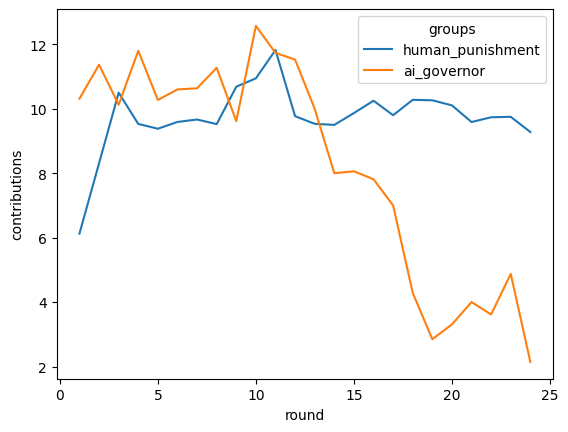

In [71]:
sns.lineplot(data=dfe, x="round", y="contributions", hue="groups", errorbar=None)

<Axes: xlabel='round', ylabel='common_good'>

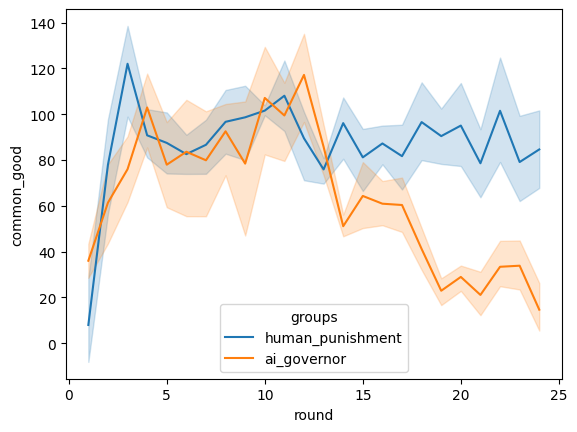

In [72]:
sns.lineplot(data=dfe, x="round", y="common_good", hue="groups")

<Axes: xlabel='round', ylabel='punishments'>

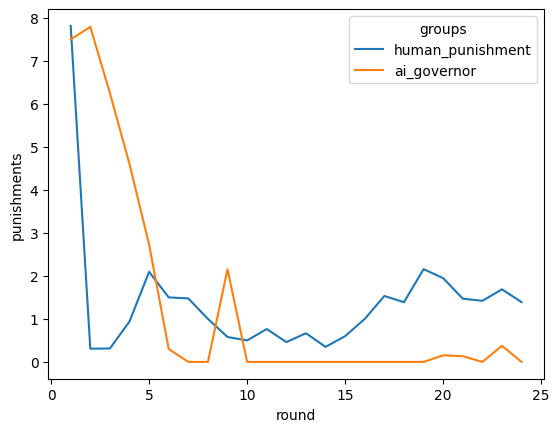

In [73]:
sns.lineplot(data=dfe, x="round", y="punishments", hue="groups", errorbar=None)

<Axes: xlabel='round', ylabel='payoff'>

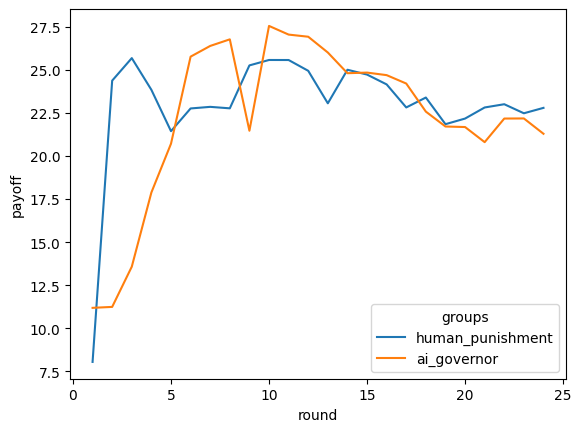

In [74]:
sns.lineplot(data=dfe, x="round", y="payoff", hue="groups", errorbar=None)

Text(0, 0.5, 'Member count')

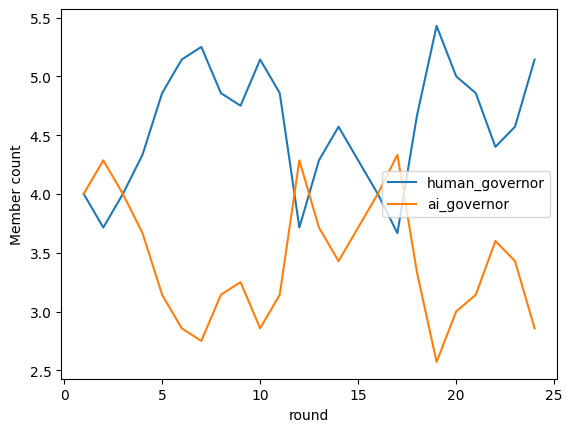

In [75]:
sns.lineplot(
    data=dfm, x="round", y="human_manager_count", errorbar=None, label="human_governor"
)
sns.lineplot(
    data=dfm, x="round", y="ai_manager_count", errorbar=None, label="ai_governor"
)
plt.ylabel("Member count")

In [76]:
dfc = dfe[
    [
        "session",
        "group_session",
        "round",
        "groups",
        "contributions",
        "punishments",
        "common_good",
        "payoff",
        "ai_governor_count",
        "human_governor_count",
    ]
]
dfc.head()

,session,group_session,round,groups,contributions,punishments,common_good,payoff,ai_governor_count,human_governor_count
0,z1awq43i,human_punishment_z1awq43i_2,1,human_punishment,14,0,72.2,24.05,4.0,4.0
1,z1awq43i,ai_governor_z1awq43i_2,1,ai_governor,1,30,34.6,-2.35,4.0,4.0
2,z1awq43i,human_punishment_z1awq43i_2,1,human_punishment,8,0,72.2,30.05,4.0,4.0
3,z1awq43i,ai_governor_z1awq43i_2,1,ai_governor,15,3,34.6,10.65,4.0,4.0
4,z1awq43i,ai_governor_z1awq43i_2,1,ai_governor,15,3,34.6,10.65,4.0,4.0


In [77]:
dfm = (
    dfe.groupby(["group_session", "round", "manager", "groups", "session"])
    .mean(numeric_only=True)
    .reset_index()
)
dfm.head()

,group_session,round,manager,groups,session,revision_id,contributions,punishments,missing_governor_input,group_idx,...,human_governor_count,group_size,payoff,contributions_mean,punishments_mean,common_good_mean,payoff_mean,contribution_delta,payoff_delta,punishment_delta
0,ai_governor_z1awq43i_2,1,ai_manager,ai_governor,z1awq43i,NaN,11.5,9.75,0.0,2.0,...,4.0,4.0,7.4,10.025316,0.620253,72.065823,24.774684,1.474684,-17.374684,9.129747
1,ai_governor_z1awq43i_2,2,ai_manager,ai_governor,z1awq43i,NaN,18.5,1.00,0.0,2.0,...,6.0,2.0,29.1,10.025316,0.620253,72.065823,24.774684,8.474684,4.325316,0.379747
2,ai_governor_z1awq43i_2,3,ai_manager,ai_governor,z1awq43i,NaN,0.0,0.00,0.0,2.0,...,7.0,1.0,20.0,10.025316,0.620253,72.065823,24.774684,-10.025316,-4.774684,-0.620253
3,ai_governor_z1awq43i_2,4,ai_manager,ai_governor,z1awq43i,NaN,0.0,0.00,0.0,2.0,...,7.0,1.0,20.0,10.025316,0.620253,72.065823,24.774684,-10.025316,-4.774684,-0.620253
4,ai_governor_z1awq43i_2,5,ai_manager,ai_governor,z1awq43i,NaN,0.0,0.00,0.0,2.0,...,7.0,1.0,20.0,10.025316,0.620253,72.065823,24.774684,-10.025316,-4.774684,-0.620253
